# 7. Regularisation vs factor models

Central banks have nowcast with **dynamic factor models** for two decades: summarise the
indicator panel with a few common factors and regress GDP on them. Principal components regression
(PCR) is the static version (the Stock-Watson "diffusion index").

PCR and ridge are close relatives. With $X = UDV^\top$:

| | weight on principal direction $j$ |
|---|---|
| OLS | 1 |
| PCR with $k$ components | 1 for $j \le k$, 0 otherwise |
| Ridge | $d_j^2/(d_j^2+\lambda)$ |

PCR is a hard cut; ridge is a smooth taper. Both assume the signal sits in the high-variance
directions of $X$. The lasso assumes something different: that a few **original** variables matter.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 4.2), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(42)

In [2]:
# The project's real data: the horizon-2 design (nowcast made at the end of the quarter)
from nowcast.features import build_all, main_spec
from nowcast.models import Standardiser
B = build_all([2])
X = B["X"][2]
X = X[[c for c in X.columns if main_spec(c)]]       # real-time output + other indicators
y = B["first"].reindex(X.index)                      # target: ONS's first published estimate
keep = y.notna() & ~X.index.isin(pd.period_range("2020Q1", "2021Q2", freq="Q"))
X, y = X[keep], y[keep]
names = list(X.columns)
print(X.shape, "quarters x features")

(108, 236) quarters x features


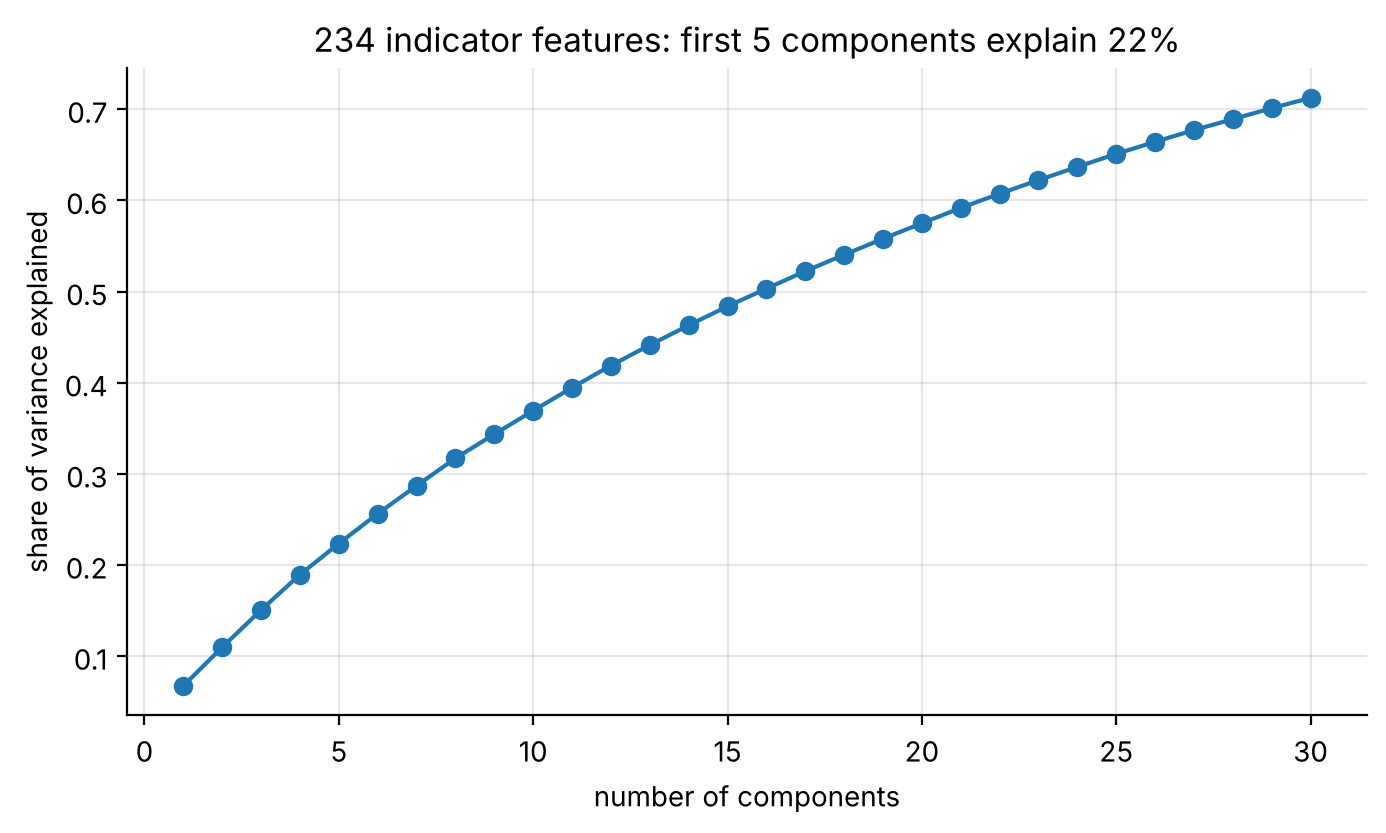

In [3]:
from sklearn.decomposition import PCA
ind_cols = [j for j, n in enumerate(names) if not n.startswith("GDP_")]
Z = Standardiser().fit(X.values).transform(X.values)[:, ind_cols]
pca = PCA().fit(Z)
cum = np.cumsum(pca.explained_variance_ratio_)
plt.plot(np.arange(1, 31), cum[:30], "o-")
plt.xlabel("number of components"); plt.ylabel("share of variance explained")
plt.title(f"{len(ind_cols)} indicator features: first 5 components explain {cum[4]:.0%}");

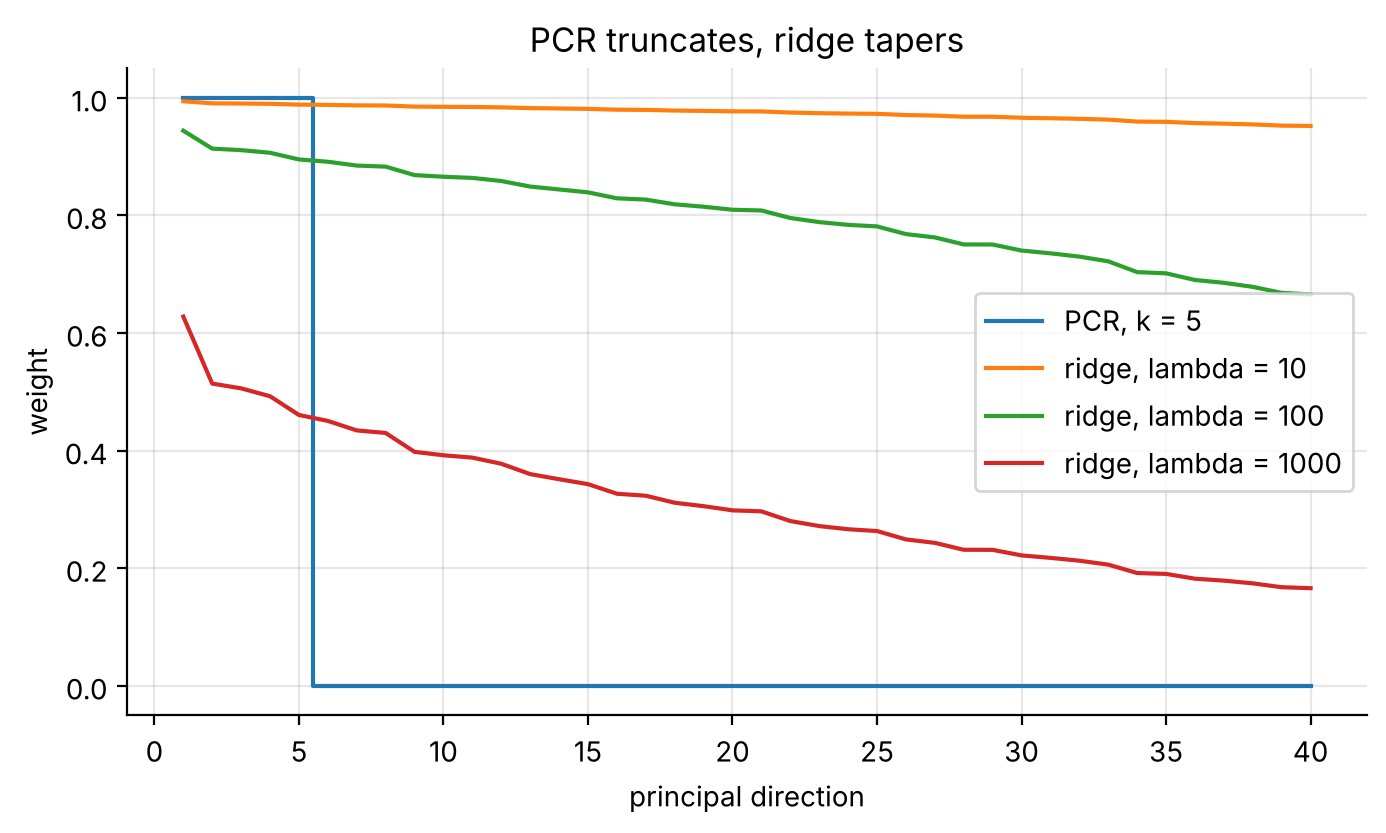

In [4]:
d = np.linalg.svd(Z, compute_uv=False)
j = np.arange(1, 41)
plt.plot(j, np.where(j <= 5, 1, 0), drawstyle="steps-mid", label="PCR, k = 5")
for lam in [10, 100, 1000]:
    plt.plot(j, d[:40]**2 / (d[:40]**2 + lam), label=f"ridge, lambda = {lam}")
plt.xlabel("principal direction"); plt.ylabel("weight"); plt.legend()
plt.title("PCR truncates, ridge tapers");

## Which wins?
It depends on the structure of the truth:

* **Dense, diffuse signal** (many small effects driven by common shocks): factors and ridge do well.
* **Sparse signal** (a few series carry the information): the lasso family does well.

GDP nowcasting sits in between: a common business cycle (dense) plus a few hard measures of
output, such as the Index of Services and Index of Production, which are close to the target itself
(sparse). The main project's backtest (notebooks/04) finds both. Early in the quarter, before any
output data exist, the factor model and ridge are the most accurate. Once output data arrive, a
two-indicator bridge equation beats every penalised model.

**Key takeaways**
* Ridge and PCR both shrink low-variance directions; ridge does it smoothly.
* Factor models are interpretable as common cycles; the lasso as a short list of indicators.
* Combining the two views often beats either (see the forecast combination in the main results).